# 2026 DL Lab3: Semi-Supervised Intel Image Classification

Before we start, please put **your name** and **SID** in following format: <br>
Hi I'm 陸仁賈, 315831000.

**Your Answer:**    
Hi I'm 黃毓峰, 315834011.

## Semi-supervised Intel Image Classification

Train a CNN from scratch using labeled images, then use pseudo-labels to learn from unlabeled images.

**Use PyTorch only. You must implement the model yourself; pre-constructed models, imported architecture blocks, pre-trained weights, extra images, and recovering hidden labels from the public source are not allowed.**

Complete every `TODO` section between the existing comment borders. Keep the data split and class order unchanged. You may adjust the architecture, augmentation and training hyperparameters.

##  Versions of used packages

We will check PyTorch version to make sure everything work properly.

In [1]:
import sys
import torch
import torchvision
print('python', sys.version.split('\n')[0])
print('torch', torch.__version__)
print('torchvision', torchvision.__version__)

python 3.12.12 (main, Feb  3 2026, 22:51:04) [Clang 21.1.4 ]
torch 2.9.1+cu126
torchvision 0.24.1+cu126


## Random Seed

Set a random seed before creating the model and starting training to make experiments more reproducible. Use the same seed when comparing settings, and try multiple seeds to check stability. Results may still differ across hardware and software versions.


In [2]:
import random
import numpy as np

SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# Prepare Data

We use [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification), provided on Kaggle by Puneet Bansal.

The six classes, in the fixed order used by this notebook, are:
- buildings
- forest
- glacier
- mountain
- sea
- street

Use only the course-provided subset. The original training and test sets are merged and deduplicated before creating four disjoint assignment splits. The additional `seg_pred` pool is not used.

**IMPORTANT: You CANNOT use extra images or look up withheld labels.**

## Unzip Data

Place `Lab3_data_intel_2026.zip` next to this notebook and unzip it. There are 3 folders inside `Lab3_data_intel_2026/`.

- `train/`: 7 subfolders total.
   - `buildings/`, `forest/`, `glacier/`, `mountain/`, `sea/`, `street/`: labeled training images.
   - `unlabel/`: unlabeled training images.
- `val/`: contains 6 folders for the same 6 classes. Labeled validation images for each class.
- `test/`: unclassified images of the testing set.

There are **1800 images in labeled training set.**  

There are **3600 images in unlabeled training set.**

There are **1200 images in validation set.**

There are **3000 images in test set.**  


## Loading the dataset

In [3]:
data_folder = './Lab3_data_intel_2026'

### Custom dataset

Build a classs inherit `torch.utils.data.Dataset`.  
Implement `__init__`, `__getitem__` and `__len__` 3 functions.  

Some operations could be there: setting location of dataset, the method of reading data, label of dataset or transform of dataset.

See [torch.utils.data.Dataset](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) for more details

In [4]:
import csv
import os.path as osp
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import DataLoader, Dataset, TensorDataset
import pandas as pd

CLASS_NAMES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
CLASS_TO_IDX = {c:i for i, c in enumerate(CLASS_NAMES)}
VALID_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

class IntelData(Dataset):
    def __init__(self, root, split='train', mode='train', transform=None, use_unlabel=False):
        self.root = Path(root)
        self.split = split
        self.mode = mode
        self.transform = transform
        self.use_unlabel = use_unlabel

        self.paths = []
        self.labels = []
        self.rel_paths = []

        # Load data from unified CSV files
        if split == 'train' and use_unlabel:
            csv_file = self.root / 'unlabeled_train.csv'
        elif split == 'train':
            csv_file = self.root / 'train.csv'
        elif split == 'val':
            csv_file = self.root / 'val.csv'
        else:  # test
            csv_file = self.root / 'test.csv'

        # Read CSV file using pandas for better handling
        df = pd.read_csv(csv_file)

        for _, row in df.iterrows():
            file_path = self.root / row['file_name']
            self.paths.append(file_path)
            self.rel_paths.append(row['file_name'])

            # Handle labels
            if split == 'test' or (split == 'train' and use_unlabel):
                # No labels for test or unlabeled data
                pass
            else:
                # For labeled data
                if pd.isna(row['groundtruth']) or row['groundtruth'] == '':
                    self.labels.append(-1)  # Invalid label for debugging
                else:
                    self.labels.append(CLASS_TO_IDX[row['groundtruth']])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        img_path = self.paths[index]
        img = Image.open(img_path).convert('RGB')
        if self.transform is not None:
            img = self.transform(img)

        if self.mode == 'test' or (self.split == 'train' and self.use_unlabel):
            return img
        label = int(self.labels[index])
        return img, torch.tensor(label, dtype=torch.long)

### Data augmentation

Data augmentation are techniques used to increase the amount of data by adding slightly modified copies of already existing data or newly created synthetic data from existing data.

PyTorch use `torchvision.transforms` to do data augmentation.
[You can see all function here.](https://docs.pytorch.org/vision/main/transforms.html)  

There are some operations may not be necessary for predict, so we should write one for train and one for others.  
**NOTICE**: Use `torchvision.transforms.v2` in this assignment.

In [5]:
from torchvision.transforms import v2 as transforms
# For TRAIN
########################################################################
# TODO: use transforms.xxx method to do some data augmentation         #
# This one is for training, find the composition to get better result  #
########################################################################

IMG_SIZE: int = 128

def compute_mean_std(dataset: Dataset, batch_size: int = 256) -> tuple[list[float], list[float]]:
    loader = DataLoader(
        dataset=dataset,
        batch_size=batch_size,
        shuffle=False,
    )
    channel_sum: torch.Tensor = torch.zeros(size=(3,), dtype=torch.float64)
    channel_sq_sum: torch.Tensor = torch.zeros(size=(3,), dtype=torch.float64)
    pixel_count: int = 0
    for images, _ in loader:
        images = images.to(dtype=torch.float64)
        channel_sum += images.sum(dim=(0, 2, 3))
        channel_sq_sum += images.pow(2).sum(dim=(0, 2, 3))
        pixel_count += images.size(0) * images.size(2) * images.size(3)
    mean: torch.Tensor = channel_sum / pixel_count
    std: torch.Tensor = (channel_sq_sum / pixel_count - mean.pow(2)).sqrt()
    return mean.tolist(), std.tolist()


stats_transform = transforms.Compose([
    transforms.Resize(size=(IMG_SIZE, IMG_SIZE)),
    transforms.ToImage(),
    transforms.ToDtype(dtype=torch.float32, scale=True),
])
stats_set = IntelData(
    root=data_folder,
    split='train',
    mode='train',
    transform=stats_transform,
)
MEAN, STD = compute_mean_std(dataset=stats_set)
print('MEAN:', MEAN)
print('STD :', STD)

transforms_train = transforms.Compose([
    transforms.RandomResizedCrop(
        size=IMG_SIZE,
        scale=(0.6, 1.0),
        ratio=(3 / 4, 4 / 3),
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(
        p=0.5,
        scale=(0.02, 0.2),
        value=0
    )
])
########################################################################
#                           End of your code                           #
########################################################################

# For VAL, TEST
########################################################################
# TODO: use transforms.xxx method to do some data augmentation         #
# This one is for validate and test,                                   #
# NOTICE some operation we usually not use in this part                #
########################################################################
transforms_test = transforms.Compose([
    transforms.Resize(size=(IMG_SIZE, IMG_SIZE)),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=MEAN, std=STD),
])
########################################################################
#                           End of your code                           #
########################################################################

MEAN: [0.42824808438497725, 0.4527323853943091, 0.44792178568193713]
STD : [0.2583000251331474, 0.25641532575922427, 0.28755688074805874]


### Instantiate dataset

Let's instantiate three `IntelData` class.
+ train_set: for labeled_training.
+ unlabeled_set: for unlabeled_training.
+ dataset_val: for validation.

In [6]:
train_set       = IntelData(data_folder, split='train', mode='train', transform=transforms_train, use_unlabel=False)
unlabeled_set   = IntelData(data_folder, split='train', mode='test',  transform=transforms_test,  use_unlabel=True)  # train/unlabel
valid_set       = IntelData(data_folder, split='val',   mode='train', transform=transforms_test,  use_unlabel=False)

num_classes = len(CLASS_NAMES)
print("The first image's shape in dataset_train :", train_set[0][0].size())
print("There are", len(train_set), "images in labeled_dataset_train.")
print("There are", len(unlabeled_set), "images in unlabeled_dataset_train.")
print("There are", len(valid_set), "images in dataset_val.")

# Verify the new format by checking a few samples
print("\nVerifying data loading with new CSV format:")
print("Train set - first sample label:", train_set[0][1].item() if len(train_set) > 0 else "No data")
print("Train set - file path:", train_set.rel_paths[0] if len(train_set) > 0 else "No data")
print("Unlabeled set - file path:", unlabeled_set.rel_paths[0] if len(unlabeled_set) > 0 else "No data")
print("Val set - first sample label:", valid_set[0][1].item() if len(valid_set) > 0 else "No data")
print("Val set - file path:", valid_set.rel_paths[0] if len(valid_set) > 0 else "No data")

The first image's shape in dataset_train : torch.Size([3, 128, 128])
There are 1800 images in labeled_dataset_train.
There are 3600 images in unlabeled_dataset_train.
There are 1200 images in dataset_val.

Verifying data loading with new CSV format:
Train set - first sample label: 5
Train set - file path: train/street/v2_58e827e2bc1e5db31c9135f25ec2a7ce.jpg
Unlabeled set - file path: train/unlabel/v2_b80f92051b52295f7d59b062094fb0fe.jpg
Val set - first sample label: 4
Val set - file path: val/sea/v2_b1f55b4b5ec9f08ad8c31ae8a7084c15.jpg


### DataLoader

`torch.utils.data.DataLoader` define how to sample from `dataset` and some other function like:
+ shuffle : set to `True` to have the data reshuffled at every epoch
+ batch_size : how many samples per batch to load

See [torch.utils.data.DataLoader](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) for more details

In [7]:
#####################################################
#            You can adjust batch_size              #
#####################################################
from typing import Any

batch_size = 64

# Increase to 2 if supported by your runtime
num_workers = 8  

loader_kwargs: dict[str, Any] = {
    "batch_size": batch_size,
    "num_workers": num_workers,
    "pin_memory": torch.cuda.is_available(),
    "persistent_workers": num_workers > 0,
}

train_loader = DataLoader(train_set, shuffle=True,  **loader_kwargs)
val_loader   = DataLoader(valid_set, shuffle=False, **loader_kwargs)

Finally! We have made all data prepared.  
Let's go develop our model.

# Self-training

## Step 1: Supervised training

### Implement CNN using PyTorch

Try to use labeled data design and train a deep convolutional network from scratch to predict the class label of a scene image.

**Again, the goal of this assignment is for you to test different convolutional structures. You cannot directly use the blocks/architectures of pre-trained models.**

### Model design

A ResNet-style CNN implemented from scratch with `torch.nn` primitives only (no `torchvision.models`, no pretrained weights).
All hyperparameters live in `ModelConfig`; reassign `MODEL_CONFIG` before building the model to run ablations, e.g. `MODEL_CONFIG = ModelConfig(activation=nn.ReLU)`.

| Stage   | Output (C × H × W) | Layers                          |
|---------|--------------------|---------------------------------|
| Input   | 3 × 128 × 128      | –                               |
| Stem    | 32 × 128 × 128     | 2 × (Conv 3×3 → BN → act)       |
| Stage 1 | 64 × 64 × 64       | 2 × ResidualBlock (first: stride 2) |
| Stage 2 | 128 × 32 × 32      | 2 × ResidualBlock (first: stride 2) |
| Stage 3 | 256 × 16 × 16      | 2 × ResidualBlock (first: stride 2) |
| Stage 4 | 384 × 8 × 8        | 2 × ResidualBlock (first: stride 2) |
| Head    | 6                  | GAP → Dropout → Linear          |

**Residual block:** $y = \sigma\big(a \cdot \mathrm{DropPath}(F(x)) + b \cdot S(x)\big)$, where $F$ = Conv 3×3 → BN → act → Conv 3×3 → BN → SE and $S$ is the shortcut.

| Component | Purpose | Reference |
|---|---|---|
| Squeeze-and-Excitation | Channel attention: $x \odot \mathrm{sigmoid}(W_2\,\sigma(W_1\,\mathrm{GAP}(x)))$ | Hu et al., CVPR 2018 |
| AvgPool shortcut | Downsampling shortcut uses AvgPool → Conv 1×1 instead of a strided 1×1 conv, so no activations are discarded | He et al., *Bag of Tricks*, CVPR 2019 |
| Zero-init residual | Last BN of each branch starts with $\gamma = 0$, so every block is an identity mapping at initialization | Goyal et al., 2017 |
| Stochastic depth | Randomly drops the residual branch per sample; drop rate grows linearly from 0 to 0.1 with depth | Huang et al., ECCV 2016 |
| LAuReL-RW (optional) | Learnable residual weights $(a, b)$; off by default, used for ablation | Menghani et al., ICML 2025 |

In [8]:
from collections.abc import Callable
from dataclasses import dataclass

import torch
from torch import nn


@dataclass(frozen=True)
class ModelConfig:
    """Hyperparameters of the residual CNN."""

    activation: Callable[[], nn.Module] = nn.GELU
    stem_channels: int = 32
    widths: tuple[int, ...] = (64, 128, 256, 512)
    depths: tuple[int, ...] = (2, 2, 2, 2)
    se_reduction: int = 16
    drop_path_rate: float = 0.2
    head_dropout: float = 0.2
    use_laurel: bool = False


class ConvBN(nn.Module):
    """Conv2d (no bias) followed by BatchNorm2d."""

    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        kernel_size: int,
        stride: int = 1,
    ) -> None:
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=kernel_size // 2,
            bias=False,
        )
        self.bn = nn.BatchNorm2d(num_features=out_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.bn(self.conv(x))


class DropPath(nn.Module):
    """Stochastic depth: drop the whole residual branch per sample."""

    def __init__(self, drop_prob: float) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob: float = 1.0 - self.drop_prob
        mask = torch.empty(size=(x.size(0), 1, 1, 1), device=x.device)
        mask = mask.bernoulli_(p=keep_prob)
        return x * mask / keep_prob

    def extra_repr(self) -> str:
        return f"drop_prob={self.drop_prob}"


class SEBlock(nn.Module):
    """Squeeze-and-Excitation channel attention."""

    def __init__(
        self,
        channels: int,
        reduction: int,
        activation: Callable[[], nn.Module],
    ) -> None:
        super().__init__()
        hidden: int = max(channels // reduction, 8)
        self.gate = nn.Sequential(
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Conv2d(in_channels=channels, out_channels=hidden, kernel_size=1),
            activation(),
            nn.Conv2d(in_channels=hidden, out_channels=channels, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.gate(x)


class ResidualBlock(nn.Module):
    """Basic residual block with SE, stochastic depth and zero-init residual.

    y = act(a * DropPath(F(x)) + b * shortcut(x)),
    where (a, b) = (1, 1), or learnable scalars when LAuReL-RW is enabled.
    """

    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int,
        activation: Callable[[], nn.Module],
        se_reduction: int,
        drop_prob: float,
        use_laurel: bool,
    ) -> None:
        super().__init__()
        last_conv = ConvBN(
            in_channels=out_channels,
            out_channels=out_channels,
            kernel_size=3,
        )
        nn.init.zeros_(last_conv.bn.weight)
        self.branch = nn.Sequential(
            ConvBN(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                stride=stride,
            ),
            activation(),
            last_conv,
            SEBlock(
                channels=out_channels,
                reduction=se_reduction,
                activation=activation,
            ),
        )

        if stride == 1 and in_channels == out_channels:
            self.shortcut: nn.Module = nn.Identity()
        else:
            self.shortcut = nn.Sequential(
                nn.AvgPool2d(kernel_size=stride) if stride > 1 else nn.Identity(),
                ConvBN(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=1,
                ),
            )

        if use_laurel:
            self.res_weights = nn.Parameter(torch.ones(2))
        else:
            self.register_buffer("res_weights", torch.ones(2))

        self.drop_path = DropPath(drop_prob=drop_prob)
        self.act = activation()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        branch = self.drop_path(self.branch(x))
        shortcut = self.shortcut(x)
        return self.act(self.res_weights[0] * branch + self.res_weights[1] * shortcut)


def init_weights(module: nn.Module) -> None:
    """Kaiming init for conv, small normal init for linear; BN keeps its own."""
    if isinstance(module, nn.Conv2d):
        nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.01)
        nn.init.zeros_(module.bias)


MODEL_CONFIG = ModelConfig()

In [9]:
from torch.nn.modules.conv import Conv2d
import torch.nn as nn
import torch.nn.functional as F
class YourCNNModel(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        ########################################################################
        # TODO: use nn.xxx method to generate a CNN model part                 #
        ########################################################################
        cfg: ModelConfig = MODEL_CONFIG

        self.stem = nn.Sequential(
            ConvBN(
                in_channels=3,
                out_channels=cfg.stem_channels,
                kernel_size=3,
            ),
            cfg.activation(),
            ConvBN(
                in_channels=cfg.stem_channels,
                out_channels=cfg.stem_channels,
                kernel_size=3,
            ),
            cfg.activation(),
        )

        num_blocks: int = sum(cfg.depths)
        drop_probs: list[float] = torch.linspace(
            start=0.0,
            end=cfg.drop_path_rate,
            steps=num_blocks,
        ).tolist()
        blocks: list[nn.Module] = []
        in_channels: int = cfg.stem_channels
        for width, depth in zip(cfg.widths, cfg.depths):
            for i in range(depth):
                blocks.append(
                    ResidualBlock(
                        in_channels=in_channels,
                        out_channels=width,
                        stride=2 if i == 0 else 1,
                        activation=cfg.activation,
                        se_reduction=cfg.se_reduction,
                        drop_prob=drop_probs[len(blocks)],
                        use_laurel=cfg.use_laurel,
                    )
                )
                in_channels = width
        self.stages = nn.Sequential(*blocks)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Flatten(),
            nn.Dropout(p=cfg.head_dropout),
            nn.Linear(in_features=in_channels, out_features=num_classes),
        )

        self.apply(init_weights)
        ########################################################################
        #                           End of your code                           #
        ########################################################################

    def forward(self, x):
        assert isinstance(x, torch.Tensor), "Input should be a torch Tensor"
        assert x.dim() == 4, "Input should be NCHW format"
        ########################################################################
        # TODO: forward your model and get output                              #
        ########################################################################
        out = self.stem(x)
        out = self.stages(out)
        out = self.head(out)
        ########################################################################
        #                           End of your code                           #
        ########################################################################
        return out

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [11]:
model = YourCNNModel(num_classes=num_classes)
model = model.to(device)

In [12]:
num_params: int = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {num_params / 1e6:.2f}M")

model.eval()
with torch.no_grad():
    dummy = torch.zeros(size=(2, 3, IMG_SIZE, IMG_SIZE), device=device)
    print(f"Output shape: {tuple(model(dummy).shape)}")

Trainable parameters: 11.25M
Output shape: (2, 6)


We have made our model!  
Next, PyTorch also provide many utility function(loss, optmizer...etc).  
You can define them in one-line.

### Define loss and optimizer

[Optimizers in pytorch](https://docs.pytorch.org/docs/stable/optim.html)  
[CrossEntropyLoss in pytorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)

In [13]:
from typing import Any

import torch.nn as nn
import torch.optim as optim
################################################################################
# TODO: Define loss and optmizer functions                                     #
# Try any loss or optimizer function and learning rate to get better result    #
# hint: torch.nn and torch.optim                                               #
################################################################################
LEARNING_RATE: float = 1e-3
WEIGHT_DECAY: float = 0.05
LABEL_SMOOTHING: float = 0.1


def build_param_groups(model: nn.Module, weight_decay: float) -> list[dict[str, Any]]:
    """Apply weight decay to conv/linear weights only, not to BN, bias or scalars."""
    decay: list[nn.Parameter] = []
    no_decay: list[nn.Parameter] = []
    for param in model.parameters():
        if not param.requires_grad:
            continue
        if param.ndim > 1:
            decay.append(param)
        else:
            no_decay.append(param)
    return [
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ]


criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = optim.AdamW(
    params=build_param_groups(model=model, weight_decay=WEIGHT_DECAY),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
)
################################################################################
#                               End of your code                               #
################################################################################
criterion = criterion.to(device)


### Train the model

#### Train function
Let's define train function.  
It will iterate input data 1 epoch and update model with optmizer.  
Finally, calculate mean loss and total accuracy.

Hint: [torch.max()](https://pytorch.org/docs/stable/generated/torch.max.html#torch-max) or [torch.argmax()](https://pytorch.org/docs/stable/generated/torch.argmax.html)

In [14]:
from tqdm import tqdm
import torch

def train(input_data, model, criterion, optimizer, epoch=None, total_epochs=None):
    '''
    Argement:
    input_data -- iterable data, typr torch.utils.data.Dataloader is prefer
    model -- nn.Module, model contain forward to predict output
    criterion -- loss function, used to evaluate goodness of model
    optimizer -- optmizer function, method for weight updating
    '''
    model.train()
    total_loss = 0.0
    total_count = 0
    acc_count = 0

    desc = f"Train | epoch {epoch}/{total_epochs}" if epoch is not None else "Train"
    pbar = tqdm(input_data, desc=desc, leave=False)

    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)

        ########################################################################
        # TODO: Forward, backward and optimize                                 #
        # 1. zero the parameter gradients                                      #
        # 2. process input through the network                                 #
        # 3. compute the loss                                                  #
        # 4. propagate gradients back into the network's parameters            #
        # 5. Update the weights of the network                                 #
        ########################################################################
        optimizer.zero_grad(set_to_none=True)
        outputs: torch.Tensor = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        ########################################################################
        #                           End of your code                           #
        ########################################################################


        ########################################################################
        # TODO: Get the counts of correctly classified images                  #
        # 1. get the model predicted result                                    #
        # 2. sum the number of this batch predicted images                     #
        # 3. sum the number of correctly classified                            #
        # 4. accumulate loss weighted by batch size                            #
        # dimension of outputs: [batch_size, number of classes]                #
        # Hint 1: use outputs.detach() if a detached tensor is needed          #
        # Hint 2: use torch.max()                                              #
        ########################################################################
        predicted: torch.Tensor = outputs.detach().argmax(dim=1)
        total_count += labels.size(0)
        acc_count += (predicted == labels).sum().item()
        total_loss += loss.item() * labels.size(0)
        ########################################################################
        #                           End of your code                           #
        ########################################################################

        running_acc = acc_count / total_count if total_count else 0.0
        lr = optimizer.param_groups[0]['lr']
        pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{running_acc:.4f}", lr=f"{lr:.6f}")

    acc  = acc_count / total_count if total_count else 0.0
    loss = total_loss / total_count if total_count else 0.0
    return acc, loss

#### Validate function
Next part is validate function.  
It works as training function without optmizer and weight-updating part.

In [15]:
def val(input_data, model, criterion, epoch=None, total_epochs=None):
    model.eval()
    total_loss = 0.0
    total_count = 0
    acc_count = 0

    desc = f"Val   | epoch {epoch}/{total_epochs}" if epoch is not None else "Val"
    pbar = tqdm(input_data, desc=desc, leave=False)

    with torch.no_grad():
        for images, labels in pbar:
            images = images.to(device)
            labels = labels.to(device)

            ####################################################################
            # TODO: Get the predicted result and loss                          #
            # 1. process input through the network                             #
            # 2. compute the loss                                              #
            # 3. get the model predicted result                                #
            # 4. get the counts of correctly classified images                 #
            # 5. accumulate loss weighted by batch size                         #
            ####################################################################
            outputs: torch.Tensor = model(images)
            loss = criterion(outputs, labels)
            predicted: torch.Tensor = outputs.argmax(dim=1)

            total_count += labels.size(0)
            acc_count += (predicted == labels).sum().item()
            total_loss += loss.item() * labels.size(0)
            ####################################################################
            #                         End of your code                         #
            ####################################################################

            running_acc = acc_count / total_count if total_count else 0.0
            pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{running_acc:.4f}")

    acc  = acc_count / total_count if total_count else 0.0
    loss = total_loss / total_count if total_count else 0.0
    return acc, loss

#### Training in a loop
Call train and test function in a loop.  
Take a break and wait.

In [16]:
################################################################################
#     You can adjust those hyper parameters to loop for max_epochs times       #
################################################################################
max_epochs: int = 200
warmup_epochs: int = 5
log_interval: int = 10

SUPERVISED_CKPT: str = "supervised.pt"
best_acc: float = -1.0

scheduler = optim.lr_scheduler.SequentialLR(
    optimizer=optimizer,
    schedulers=[
        optim.lr_scheduler.LinearLR(
            optimizer=optimizer,
            start_factor=0.1,
            total_iters=warmup_epochs,
        ),
        optim.lr_scheduler.CosineAnnealingLR(
            optimizer=optimizer,
            T_max=max_epochs - warmup_epochs,
            eta_min=1e-5,
        ),
    ],
    milestones=[warmup_epochs],
)

train_acc_list: list[float] = []
train_loss_list: list[float] = []
val_acc_list: list[float] = []
val_loss_list: list[float] = []

for epoch in range(1, max_epochs + 1):
    train_acc, train_loss = train(
        input_data=train_loader,
        model=model,
        criterion=criterion,
        optimizer=optimizer,
        epoch=epoch,
        total_epochs=max_epochs,
    )
    val_acc, val_loss = val(
        input_data=val_loader,
        model=model,
        criterion=criterion,
        epoch=epoch,
        total_epochs=max_epochs,
    )
    lr: float = optimizer.param_groups[0]["lr"]
    scheduler.step()

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), SUPERVISED_CKPT)

    train_acc_list.append(train_acc)
    train_loss_list.append(train_loss)
    val_acc_list.append(val_acc)
    val_loss_list.append(val_loss)

    if epoch % log_interval == 0:
        print("=" * 20, f"Epoch {epoch}/{max_epochs}", "=" * 20)
        print(f"Train Acc: {train_acc:.6f} | Train Loss: {train_loss:.6f}")
        print(f"  Val Acc: {val_acc:.6f} |   Val Loss: {val_loss:.6f} | LR: {lr:.6f}")

print(f"Best validation accuracy: {best_acc:.4f}")
################################################################################
#                               End of your code                               #
################################################################################

==================== Epoch 10/200 ====================
Train Acc: 0.616667 | Train Loss: 1.200220
  Val Acc: 0.691667 |   Val Loss: 1.108825 | LR: 0.000999


==================== Epoch 20/200 ====================
Train Acc: 0.695556 | Train Loss: 1.061395
  Val Acc: 0.745000 |   Val Loss: 0.937526 | LR: 0.000987


==================== Epoch 30/200 ====================
Train Acc: 0.735556 | Train Loss: 0.977843
  Val Acc: 0.808333 |   Val Loss: 0.864164 | LR: 0.000963


==================== Epoch 40/200 ====================
Train Acc: 0.758333 | Train Loss: 0.922406
  Val Acc: 0.813333 |   Val Loss: 0.831159 | LR: 0.000928


==================== Epoch 50/200 ====================
Train Acc: 0.777222 | Train Loss: 0.889203
  Val Acc: 0.859167 |   Val Loss: 0.739923 | LR: 0.000881


...

==================== Epoch 160/200 ====================
Train Acc: 0.907778 | Train Loss: 0.623589
  Val Acc: 0.882500 |   Val Loss: 0.673898 | LR: 0.000114


==================== Epoch 170/200 ====================
Train Acc: 0.915556 | Train Loss: 0.613240
  Val Acc: 0.894167 |   Val Loss: 0.662231 | LR: 0.000070


==================== Epoch 180/200 ====================
Train Acc: 0.926111 | Train Loss: 0.605989
  Val Acc: 0.896667 |   Val Loss: 0.661365 | LR: 0.000038


==================== Epoch 190/200 ====================
Train Acc: 0.926111 | Train Loss: 0.602059
  Val Acc: 0.886667 |   Val Loss: 0.667676 | LR: 0.000018


==================== Epoch 200/200 ====================
Train Acc: 0.915556 | Train Loss: 0.612910
  Val Acc: 0.893333 |   Val Loss: 0.661775 | LR: 0.000010
Best validation accuracy: 0.8967


#### Visualize accuracy and loss

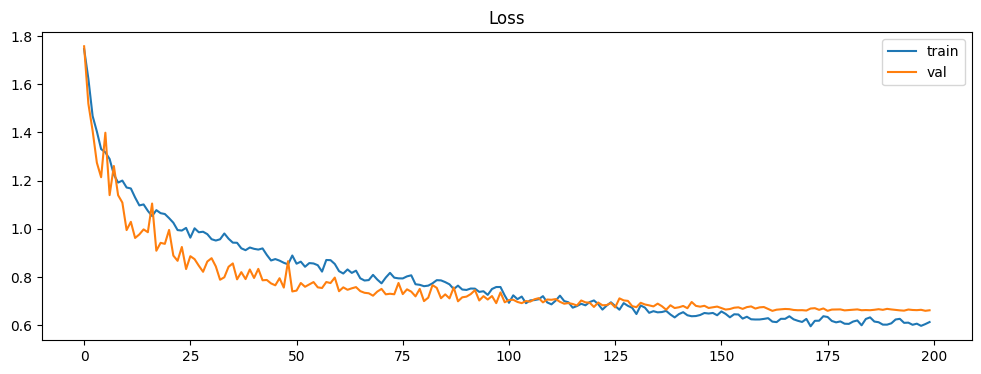

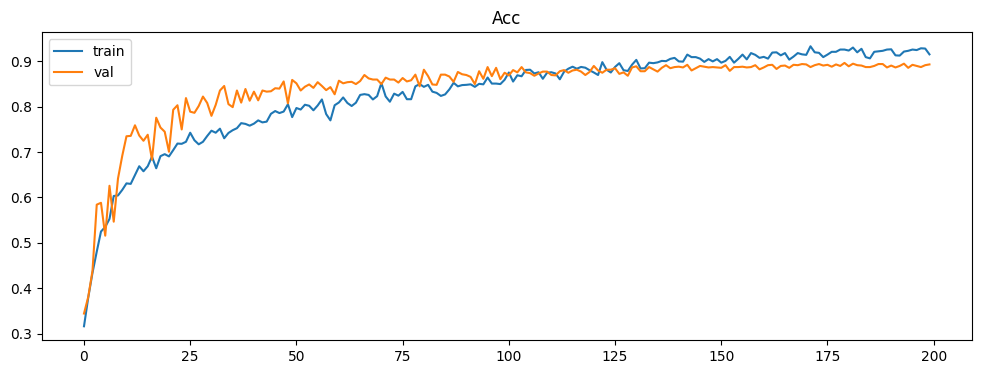

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(range(len(train_loss_list)), train_loss_list)
plt.plot(range(len(val_loss_list)), val_loss_list)
plt.legend(['train', 'val'])
plt.title('Loss')
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(range(len(train_acc_list)), train_acc_list)
plt.plot(range(len(val_acc_list)), val_acc_list)
plt.legend(['train', 'val'])
plt.title('Acc')
plt.show()

finish training your classifier, next you should use this classifer to predict unlabel images with pseduo label.

## Step2: Use unlabeled data to enhance model performance

In [18]:
# load the trained classifier weights
ckpt = torch.load(SUPERVISED_CKPT, map_location=device, weights_only=True)
model.load_state_dict(ckpt)

<All keys matched successfully>

In [19]:
# Keep image indices instead of loading all unlabeled images into memory.
# Rerun this cell when restarting Step 2.
unlabeled_indices = list(range(len(unlabeled_set)))

class PseudoLabelData(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image_path = self.paths[index]
        with Image.open(image_path) as image:
            image = image.convert('RGB')
            image = self.transform(image)

        label = self.labels[index]
        label = torch.tensor(label, dtype=torch.long)
        return image, label

print('Unlabeled pool size:', len(unlabeled_indices))

Unlabeled pool size: 3600


### Use the trained classifier to generate pseudo-labels.

In [20]:
from torch.utils.data import ConcatDataset, Subset

###########################################################
#   You can adjust the threshold to get better results!   #
###########################################################
def get_pseudo_labels(model, threshold=0.9):
    model.eval()
    paths_keep = []
    labels_keep = []
    remove_indices = []

    remaining_set = Subset(unlabeled_set, unlabeled_indices)

    loader = DataLoader(
        remaining_set,
        shuffle=False,
        **loader_kwargs
    )
    offset = 0

    ################################################################################
    # TODO: Generate pseudo-labels for the remaining unlabeled images.             #
    # 1. Forward the images through the model using torch.no_grad().               #
    # 2. Apply softmax to obtain class probabilities.                              #
    # 3. Keep predictions whose confidence reaches the threshold.                  #
    # 4. Collect the accepted image paths and predicted labels.                    #
    # 5. Add accepted pool positions to remove_indices for later removal.          #
    ################################################################################
    with torch.no_grad():
        for images in tqdm(loader, desc='Pseudo-labeling', leave=False):
            images = images.to(device)

            probs: torch.Tensor = F.softmax(model(images), dim=1)
            confidences, predictions = probs.max(dim=1)
            is_confident: torch.Tensor = confidences >= threshold
            accepted: list[int] = is_confident.nonzero(as_tuple=True)[0].tolist()
            predictions = predictions.cpu()

            for j in accepted:
                position: int = offset + j
                paths_keep.append(unlabeled_set.paths[unlabeled_indices[position]])
                labels_keep.append(int(predictions[j]))
                remove_indices.append(position)

            offset += len(images)
    ################################################################################
    #                               End of your code                               #
    ################################################################################

    # Delete backwards so earlier positions do not shift.
    for index in reversed(remove_indices):
        del unlabeled_indices[index]

    pseudo_dataset = PseudoLabelData(
        paths_keep,
        labels_keep,
        transforms_train
    )

    taken = len(pseudo_dataset)
    remaining = len(unlabeled_indices)

    print(f'Labeled {taken} images this round. Remaining unlabeled: {remaining}')

    return pseudo_dataset, taken

### Redefine your optimizer if you want

In [21]:
################################################################################
# TODO: Define loss and optmizer functions                                     #
# Try any loss or optimizer function and learning rate to get better result    #
# hint: torch.nn and torch.optim                                               #
################################################################################
import math

SELF_TRAIN_LR: float = 5e-4
SELF_TRAIN_MIN_LR: float = 1e-5


def cosine_lr(
    epoch: int,
    total_epochs: int,
    base_lr: float,
    min_lr: float,
) -> float:
    """Cosine-annealed learning rate for a 0-based epoch."""
    progress: float = epoch / max(total_epochs - 1, 1)
    return min_lr + 0.5 * (base_lr - min_lr) * (1.0 + math.cos(math.pi * progress))


criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = optim.AdamW(
    params=build_param_groups(model=model, weight_decay=WEIGHT_DECAY),
    lr=SELF_TRAIN_LR,
    betas=(0.9, 0.999),
)
################################################################################
#                               End of your code                               #
################################################################################
criterion = criterion.to(device)

### Train the model

Every `N` epochs, use `get_pseudo_labels` to label the remaining unlabeled images.

Keep high-confidence predictions and remove those images from the unlabeled pool.

Combine the original labeled data with **all accumulated pseudo-labeled data**, then build a new DataLoader.

Previously accepted pseudo-labels stay unchanged.


In [22]:
################################################################################
# You can adjust the number of epochs, update interval, and threshold.         #
################################################################################
n_epochs = 200
N = 5  # Add new pseudo-labels every N epochs.
log_interval = 10 # Log every N epochs like supervised training.
threshold = 0.9
SELF_TRAIN_CKPT = 'self_training.pt'

best_acc, _ = val(val_loader, model, criterion)
torch.save(model.state_dict(), SELF_TRAIN_CKPT)

current_train_dataset = train_set
train_loader_ssl = train_loader
all_pseudo_datasets = []
total_pseudo = 0

for epoch in range(n_epochs):
    ################################################################################
    # TODO: Construct the training dataset for semi-supervised learning.           #
    # 1. Every N epochs, call get_pseudo_labels on the remaining unlabeled data.   #
    # 2. Add the newly accepted pseudo-label dataset to all_pseudo_datasets.       #
    # 3. Combine train_set with ALL accumulated pseudo-label datasets.             #
    # 4. Create a new DataLoader for the combined dataset.                         #
    # Hint: ConcatDataset and DataLoader.                                          #
    ################################################################################
    if epoch % N == 0:
        pseudo_dataset, taken = get_pseudo_labels(model=model, threshold=threshold)
        if taken > 0:
            all_pseudo_datasets.append(pseudo_dataset)
            total_pseudo += taken
            current_train_dataset = ConcatDataset(
                datasets=[train_set, *all_pseudo_datasets],
            )
            train_loader_ssl = DataLoader(
                dataset=current_train_dataset,
                shuffle=True,
                **loader_kwargs,
            )

    # Cosine-annealed learning rate over the whole self-training stage
    epoch_lr: float = cosine_lr(
        epoch=epoch,
        total_epochs=n_epochs,
        base_lr=SELF_TRAIN_LR,
        min_lr=SELF_TRAIN_MIN_LR,
    )
    for param_group in optimizer.param_groups:
        param_group["lr"] = epoch_lr
    ################################################################################
    #                               End of your code                               #
    ################################################################################

    train_acc, train_loss = train(
        train_loader_ssl,
        model,
        criterion,
        optimizer,
        epoch=epoch + 1,
        total_epochs=n_epochs
    )
    
    valid_acc, valid_loss = val(
        val_loader,
        model,
        criterion,
        epoch=epoch + 1,
        total_epochs=n_epochs
    )
    
    lr = optimizer.param_groups[0]['lr']

    if (epoch + 1) % log_interval == 0:
        print('=' * 20, f'Epoch {epoch+1}/{n_epochs}', '=' * 20)
        print('Train Acc: {:.6f} | Train Loss: {:.6f}'.format(train_acc, train_loss))
        print('  Val Acc: {:.6f} |   Val Loss: {:.6f} | LR: {:.6f}'.format(valid_acc, valid_loss, lr))
        print('Dataset Size: {} (original: {}, pseudo: {})'.format(len(current_train_dataset), len(train_set), total_pseudo))

    if valid_acc > best_acc:
        best_acc = valid_acc
        torch.save(model.state_dict(), SELF_TRAIN_CKPT)
        if (epoch + 1) % log_interval != 0: 
            print('[{:03d}/{:03d}] saving model with acc {:.3f}'.format(epoch + 1, n_epochs, best_acc))

print('Best validation accuracy:', best_acc)

Labeled 1852 images this round. Remaining unlabeled: 1748


Labeled 197 images this round. Remaining unlabeled: 1551


==================== Epoch 10/200 ====================
Train Acc: 0.922837 | Train Loss: 0.605586
  Val Acc: 0.885000 |   Val Loss: 0.675541 | LR: 0.000498
Dataset Size: 3849 (original: 1800, pseudo: 2049)


Labeled 140 images this round. Remaining unlabeled: 1411


Labeled 128 images this round. Remaining unlabeled: 1283


...

Labeled 0 images this round. Remaining unlabeled: 456


==================== Epoch 190/200 ====================
Train Acc: 0.971481 | Train Loss: 0.500250
  Val Acc: 0.907500 |   Val Loss: 0.638856 | LR: 0.000013
Dataset Size: 4944 (original: 1800, pseudo: 3144)


Labeled 0 images this round. Remaining unlabeled: 456


Labeled 0 images this round. Remaining unlabeled: 456


==================== Epoch 200/200 ====================
Train Acc: 0.967435 | Train Loss: 0.500796
  Val Acc: 0.901667 |   Val Loss: 0.641109 | LR: 0.000010
Dataset Size: 4944 (original: 1800, pseudo: 3144)
Best validation accuracy: 0.9133333333333333


### Predict Result

**How to upload**

1. Click the folder icon in the left hand side of Colab.
2. Right click "result.csv". Select "Download".
3. To kaggle. Click "Submit Predictions"
4. Upload the result.csv.

In [23]:
# if you wanna load previous best model
ckpt = torch.load('self_training.pt', map_location=device)
model.load_state_dict(ckpt)

<All keys matched successfully>

In [24]:
test_set = IntelData(data_folder, split='test', mode='test', transform=transforms_test)
test_loader = DataLoader(
    test_set,
    batch_size=batch_size,
    num_workers=num_workers,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)

In [25]:
def predict(input_data, model):
    model.eval()
    output_list = []
    with torch.no_grad():
        for images in input_data:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            output_list.extend(predicted.to('cpu').numpy().tolist())
    return output_list

In [26]:
pred_indices = predict(test_loader, model)

with open('result.csv', 'w', newline='') as csvFile:
    writer = csv.DictWriter(csvFile, fieldnames=['ID', 'label'])
    writer.writeheader()
    for filename, pred in zip(test_set.paths, pred_indices):
        filename = osp.basename(filename)  # Extract just the filename
        writer.writerow({'ID': filename, 'label': CLASS_NAMES[int(pred)]})

print("Saved predictions to result.csv")

Saved predictions to result.csv
